# Avance 4. Modelos alternativos

**Equipo 57 — Proyecto Integrador (Gpo 10)**
Alejandro Agustín Ahedo González (A01797242) · Andrés Roberto Osuna González (A01796264) · Sandra Luz Cervantes Espinoza (A01796937)

Profesores: Dra. Liliana Ibeth Barbosa Santillán, Dra. Grettel Barceló Alonso y Dr. Luis Eduardo Falcón Morales
Socio formador: CLEAR (Coalition for Language Equity in AI Research)

---


**Evaluación Comparativa y Optimización de Modelos ASR**

En el campo del aprendizaje automático y el procesamiento de lenguaje natural, la selección de la arquitectura adecuada es un factor determinante para el éxito de una tarea. Diferentes algoritmos y modelos presentan capacidades de generalización y rendimiento variadas frente a un mismo conjunto de datos. Por lo tanto, un enfoque riguroso requiere la exploración de múltiples alternativas antes de consolidar una solución final.  
El presente cuaderno de trabajo documenta el desarrollo y la evaluación de un sistema de Reconocimiento Automático del Habla (ASR) utilizando el corpus multilingüe FLEURS. Dado que distintas arquitecturas exhiben comportamientos óptimos bajo condiciones específicas de procesamiento y recursos computacionales, este avance metodológico aborda un ciclo completo de experimentación, comparación y refinamiento técnico.   

**Objetivos y Fases del Avance**

Para cumplir con los requerimientos de análisis y optimización, este documento cubre las siguientes etapas clave:Construcción de Múltiples Arquitecturas: Se implementan y evalúan diversos modelos individuales (no basados en ensambles) utilizando arquitecturas de vanguardia (tales como **Whisper, Qwen-ASR, SeamlessM4T y Omnilingual ASR**) con configuraciones adaptadas a la memoria VRAM disponible.   

**Evaluación y Comparación de Rendimiento:**

Se analizan cuantitativamente los resultados obtenidos por cada modelo utilizando métricas estándar de precisión, como la Tasa de Error de Palabra (WER), además de evaluar los tiempos de inferencia por muestra.Selección de los Mejores Modelos: A partir de los resultados comparativos globales y por idioma, se identifican las dos arquitecturas con el desempeño más sobresaliente.

**Ajuste y Optimización:**
Se ajustan las configuraciones, parámetros de inferencia y estrategias de normalización de texturas de los dos modelos seleccionados para explotar al máximo su potencial predictivo.   

**Selección del Modelo Individual Final:**
 Se determina y justifica la elección de la arquitectura definitiva que ofrece el mejor equilibrio entre precisión, robustez y eficiencia operativa para la tarea de transcripción de voz.

**Requisitos para ejecutarlo:** entorno con **GPU** (una T4 basta; en CPU funciona, pero tarda más) y, en Google Drive, la caché de audio `fleurs_cache_seed42_n50` y el archivo `fleurs_results/avance2_features.csv` que generó el Avance 2. Se ejecuta de principio a fin con *Entorno de ejecución → Ejecutar todas*.

In [ ]:
!pip -q install -U \
    "datasets<3.0.0" \
    transformers \
    accelerate \
    evaluate \
    jiwer \
    soundfile \
    librosa \
    sentencepiece \
    huggingface_hub

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.6.1 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 2.3.0 which is incompatible.


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    print("⚠️ No GPU available.")
    print("Go to Runtime > Change runtime type > GPU")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
VRAM: 94.97 GB


**1. Construcción de modelos individuales**

El objetivo de esta etapa es construir y evaluar diferentes modelos individuales de reconocimiento automático del habla (Automatic Speech Recognition, ASR), con la finalidad de identificar cuál presenta el mejor desempeño en una tarea de transcripción multilingüe. Este análisis permite estudiar cómo se comportan distintas arquitecturas y enfoques de modelado ante audios de diferentes idiomas, considerando que cada modelo puede presentar fortalezas y limitaciones particulares dependiendo de las características del idioma, la pronunciación, la estructura lingüística y las condiciones de la señal de audio.

Para realizar la evaluación se utiliza el conjunto de datos FLEURS, un recurso de evaluación multilingüe que permite trabajar con grabaciones de voz y sus correspondientes transcripciones de referencia. La utilización de un conjunto de datos común permite comparar los resultados de los modelos bajo condiciones de evaluación consistentes, siempre que se utilicen las mismas muestras de audio y los mismos criterios de preprocesamiento y evaluación.

**1.1. Selección de los modelos**

Se consideran diferentes modelos de reconocimiento automático del habla, entre ellos Whisper Large-v3, Qwen3-ASR-0.6B, SeamlessM4T y Omnilingual ASR CTC 300M. Cada uno se ejecuta de manera independiente, sin combinar sus predicciones con las de otros modelos. Esto permite analizar el desempeño particular de cada alternativa y determinar sus ventajas y limitaciones dentro del problema planteado.

La selección de modelos con características y arquitecturas diferentes permite explorar distintas estrategias para transformar una señal de audio en una secuencia de texto. Asimismo, posibilita estudiar si existen diferencias importantes en la precisión de las transcripciones, el tiempo requerido para procesar los audios y la cobertura de los idiomas evaluados.

Para completar la comparación solicitada en esta etapa, se incorporarán al experimento al menos dos modelos individuales adicionales, de manera que se evalúen seis alternativas. La inclusión de nuevos candidatos permitirá ampliar el análisis y evitar que la selección del modelo final dependa únicamente de un grupo reducido de opciones.

**1.2. Preparación del conjunto de datos**

El conjunto de datos FLEURS se utiliza como fuente de audios y transcripciones de referencia para evaluar los modelos. Se seleccionan muestras de los idiomas incluidos en el experimento y se establece un procedimiento de preparación que permita alimentar cada modelo con entradas compatibles con sus respectivos requisitos.

Cuando se utiliza una muestra de datos en lugar del conjunto completo, se fija una semilla aleatoria para favorecer la reproducibilidad de la selección. De esta manera, es posible repetir el experimento y comparar las alternativas utilizando las mismas observaciones, siempre que se mantengan las condiciones de selección y los filtros aplicados.

Antes de iniciar las transcripciones, se verifican los elementos necesarios para la evaluación: disponibilidad del audio, transcripción de referencia, identificación del idioma y compatibilidad de las entradas con cada modelo. También se considera que los diferentes modelos pueden requerir formatos de audio, parámetros de configuración o identificadores de idioma específicos.

La comparación debe realizarse sobre el mismo conjunto de audios para todos los modelos que admitan su procesamiento. Si algún modelo no es compatible con determinado idioma o una muestra no puede procesarse, esta situación debe registrarse explícitamente para evitar comparaciones injustas o conclusiones basadas en conjuntos de evaluación diferentes.

In [ ]:
from datasets import get_dataset_config_names, load_dataset
from huggingface_hub import login
import os

try:
    from google.colab import userdata
    hf_token = userdata.get("HUGGING_FACE")
except Exception:
    hf_token = os.environ.get("HUGGING_FACE")

if hf_token:
    print("Logging in to Hugging Face...")
    login(token=hf_token)
else:
    print("Warning: HUGGING_FACE token not found in secrets.")

print("Fetching all FLEURS language configurations...")
# Seleccionar solo 8 idiomas compatibles con los 4 modelos (especialmente Qwen3-ASR)
all_fleurs_langs = [
    "en_us", "es_419", "fr_fr", "de_de",
    "it_it", "ru_ru", "ja_jp", "cmn_hans_cn"
]

# FIX (Oct 2026): each model gets its own language code.
# Before, Whisper received Qwen's code and failed on cmn, jv, nb and fil.
WHISPER_FIX = {"cmn": "zh", "jv": "jw", "nb": "no", "fil": "tl"}
QWEN_FIX = {"cmn": "zh"}

LANGUAGES = {}
for lang_code in all_fleurs_langs:
    base_code = lang_code.split("_")[0]
    LANGUAGES[lang_code] = {
        "name": lang_code,
        "whisper": WHISPER_FIX.get(base_code, base_code),
        "qwen": QWEN_FIX.get(base_code, base_code),
        "omni": lang_code,
        "seamless": base_code,
    }

print(f"\n{len(LANGUAGES)} languages configured")
print("Preview:", dict(list(LANGUAGES.items())[:3]))

Fetching all FLEURS language configurations...

8 languages configured
Preview: {'en_us': {'name': 'en_us', 'whisper': 'en', 'qwen': 'en', 'omni': 'en_us', 'seamless': 'en'}, 'es_419': {'name': 'es_419', 'whisper': 'es', 'qwen': 'es', 'omni': 'es_419', 'seamless': 'es'}, 'fr_fr': {'name': 'fr_fr', 'whisper': 'fr', 'qwen': 'fr', 'omni': 'fr_fr', 'seamless': 'fr'}}


In [ ]:
SAMPLES_PER_LANGUAGE = 50

SEED = 42

print("Samples per language:", SAMPLES_PER_LANGUAGE)
print("Total audio clips:", len(LANGUAGES) * SAMPLES_PER_LANGUAGE)

Samples per language: 50
Total audio clips: 400


In [ ]:
# ============================================================
# LOAD FLEURS (parallel + cache)
# ============================================================

import os, pickle, time
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed
from datasets import load_dataset

USE_DRIVE_CACHE = True   # True: the cache survives when the session ends
N_WORKERS = 12           # lower to 4 if you get network errors

if USE_DRIVE_CACHE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        CACHE_DIR = f"/content/drive/MyDrive/fleurs_cache_seed{SEED}_n{SAMPLES_PER_LANGUAGE}"
    except Exception as e:
        print("Could not mount Google Drive, using local disk:", e)
        CACHE_DIR = f"/content/fleurs_cache_seed{SEED}_n{SAMPLES_PER_LANGUAGE}"
else:
    CACHE_DIR = f"/content/fleurs_cache_seed{SEED}_n{SAMPLES_PER_LANGUAGE}"
os.makedirs(CACHE_DIR, exist_ok=True)
print("Cache:", CACHE_DIR)


def _load_one(lang_code):
    path = os.path.join(CACHE_DIR, f"{lang_code}.pkl")
    if os.path.exists(path):
        with open(path, "rb") as f:
            return lang_code, pickle.load(f), "cache"

    ds = load_dataset("google/fleurs", lang_code, split="test", streaming=True)
    ds = ds.shuffle(seed=SEED, buffer_size=500).take(SAMPLES_PER_LANGUAGE)

    samples = []
    for s in ds:
        samples.append({
            "id": s["id"],
            "transcription": s["transcription"],
            "language": s.get("language", lang_code),
            "audio": {
                "array": np.asarray(s["audio"]["array"], dtype=np.float32),
                "sampling_rate": s["audio"]["sampling_rate"],
            },
        })

    with open(path, "wb") as f:
        pickle.dump(samples, f)
    return lang_code, samples, "downloaded"


datasets_fleurs = {}
failed_loads = {}
t0 = time.time()
langs = [l for l in LANGUAGES if l != "all"]

with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
    futures = {pool.submit(_load_one, l): l for l in langs}
    for n, fut in enumerate(as_completed(futures), 1):
        lang = futures[fut]
        try:
            code, samples, source = fut.result()
            datasets_fleurs[code] = samples
            print(f"[{n}/{len(langs)}] {code}: {len(samples)} samples ({source})")
        except Exception as e:
            failed_loads[lang] = str(e)[:150]
            print(f"[{n}/{len(langs)}] {lang}: ERROR {str(e)[:150]}")

# keep the original language order
datasets_fleurs = {l: datasets_fleurs[l] for l in langs if l in datasets_fleurs}

print(f"\nFLEURS ready: {len(datasets_fleurs)} languages in {(time.time() - t0) / 60:.1f} min")
if failed_loads:
    print("Failed:", list(failed_loads), "— run the cell again; cached languages are not downloaded twice.")

Mounted at /content/drive
Cache: /content/drive/MyDrive/fleurs_cache_seed42_n50
[1/8] en_us: 50 samples (cache)
[2/8] cmn_hans_cn: 50 samples (cache)
[3/8] fr_fr: 50 samples (cache)
[4/8] ru_ru: 50 samples (cache)
[5/8] ja_jp: 50 samples (cache)
[6/8] de_de: 50 samples (cache)
[7/8] es_419: 50 samples (cache)
[8/8] it_it: 50 samples (cache)

FLEURS ready: 8 languages in 0.0 min


In [ ]:
lang_code = "es_419"

sample = datasets_fleurs[lang_code][0]

print("Language:", LANGUAGES[lang_code]["name"])
print("ID:", sample["id"])
print("Transcription:")
print(sample["transcription"])

print("\nAudio:")
print(sample["audio"])

print("\nSampling rate:")
print(sample["audio"]["sampling_rate"])

Language: es_419
ID: 1839
Transcription:
imagínese la pista de esquí como una ruta de senderismo

Audio:
{'array': array([ 0.        ,  0.        ,  0.        , ..., -0.00018376,
       -0.00017244, -0.00013667], dtype=float32), 'sampling_rate': 16000}

Sampling rate:
16000


In [ ]:
# ============================================================
# WHISPER LARGE-V3
# ============================================================

import torch
from transformers import pipeline

DEVICE = 0 if torch.cuda.is_available() else -1

whisper_pipe = pipeline(
    "automatic-speech-recognition",
    model="openai/whisper-large-v3",
    device=DEVICE,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
)

print("Whisper Large-v3 completed")

config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1259 [00:00<?, ?it/s]

...

normalizer.json:   0%|          | 0.00/52.7k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.07k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

Whisper Large-v3 completed


In [ ]:
# ============================================================
# QWEN3-ASR
# ============================================================

from transformers import AutoProcessor, Qwen3ASRForConditionalGeneration

QWEN_MODEL = "Qwen/Qwen3-ASR-0.6B-hf"

qwen_processor = AutoProcessor.from_pretrained(QWEN_MODEL)

qwen_model = Qwen3ASRForConditionalGeneration.from_pretrained(
    QWEN_MODEL,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto",
)

qwen_model.eval()

print("Qwen3-ASR loaded")

processor_config.json:   0%|          | 0.00/487 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.56GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/611 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/165 [00:00<?, ?B/s]

Qwen3-ASR loaded


In [ ]:
import torch

# ============================================================
# DEVICE
# ============================================================

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print("Device:", device)

Device: cuda


In [ ]:
# ============================================================
#  OMNILINGUAL ASR - HUGGING FACE VERSION
# ============================================================

!pip install -q transformers accelerate sentencepiece


import torch

from transformers import (
    AutoProcessor,
    AutoModelForCTC
)

OMNI_MODEL = "aadel4/omniASR-CTC-300M"

omni_processor = AutoProcessor.from_pretrained(
    OMNI_MODEL
)

omni_model = AutoModelForCTC.from_pretrained(
    OMNI_MODEL
)

omni_model = omni_model.to(device)

omni_model.eval()

print("Omnilingual ASR loaded")
print("Device:", device)

preprocessor_config.json:   0%|          | 0.00/187 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/233 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/145k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.30GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

Omnilingual ASR loaded
Device: cuda


**1.3. Ejecución de los modelos**

Cada modelo recibe los audios seleccionados y genera una transcripción de manera independiente. Durante la ejecución se registran las predicciones obtenidas y el tiempo de inferencia, procurando mantener condiciones de ejecución comparables.

Las transcripciones generadas se contrastan posteriormente con las transcripciones de referencia de FLEURS. Para que la comparación sea consistente, se aplica un procedimiento de normalización de texto definido previamente, que puede incluir la estandarización de mayúsculas y minúsculas, la eliminación de elementos de puntuación y el tratamiento de espacios en blanco, según los criterios establecidos en el experimento.

Es importante mantener el mismo criterio de normalización para todos los modelos, ya que las diferencias en el tratamiento del texto pueden modificar artificialmente las métricas de error. En el caso de los idiomas con características particulares de escritura o segmentación, se debe verificar que el procedimiento de evaluación sea apropiado para el idioma correspondiente.

In [ ]:
import torch
import numpy as np

def transcribe_seamless(audio_data, tgt_lang):
    """
    Transcribes a single audio clip with SeamlessM4T.
    """
    audio = np.asarray(audio_data["array"], dtype=np.float32)
    sampling_rate = audio_data["sampling_rate"]

    if audio.ndim > 1:
        audio = np.mean(audio, axis=0)
    audio = np.squeeze(audio)

    inputs = processor(audio=audio, sampling_rate=sampling_rate, return_tensors="pt")
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model.generate(**inputs, tgt_lang=tgt_lang)

    prediction = processor.batch_decode(outputs, skip_special_tokens=True)[0]
    return prediction.strip()

def transcribe_seamless_batch(audio_list, tgt_lang):
    """
    Transcribes a batch of audio clips with SeamlessM4T, using padding.
    """
    processed_audios = []
    for audio_data in audio_list:
        arr = np.asarray(audio_data["array"], dtype=np.float32)
        if arr.ndim > 1:
            arr = np.mean(arr, axis=0)
        processed_audios.append(np.squeeze(arr))

    inputs = processor(audio=processed_audios, sampling_rate=16000, return_tensors="pt", padding=True)
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model.generate(**inputs, tgt_lang=tgt_lang)

    predictions = processor.batch_decode(outputs, skip_special_tokens=True)
    return [p.strip() for p in predictions]

In [ ]:
# ============================================================
# SeamlessM4T
# ============================================================
!pip install -q transformers accelerate sentencepiece librosa soundfile

In [ ]:
import torch
from transformers import AutoProcessor, SeamlessM4Tv2ForSpeechToText

MODEL_NAME = "facebook/seamless-m4t-v2-large"

processor = AutoProcessor.from_pretrained(MODEL_NAME)

model = SeamlessM4Tv2ForSpeechToText.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16
)

if torch.cuda.is_available():
    model = model.to("cuda")
elif torch.backends.mps.is_available():
    model = model.to("mps")
else:
    model = model.to("cpu")

print("SeamlessM4T loaded")

preprocessor_config.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.72k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/19.7k [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B / 5.17MB            

tokenizer.model: downloading bytes:           |  0.00B            

...

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/1429 [00:00<?, ?it/s]

[transformers] SeamlessM4Tv2ForSpeechToText LOAD REPORT from: facebook/seamless-m4t-v2-large
Key                                                                           | Status     |  | 
------------------------------------------------------------------------------+------------+--+-
t2u_model.model.encoder.layers.{0, 1, 2, 3, 4, 5}.self_attn.k_proj.weight     | UNEXPECTED |  | 
vocoder.hifi_gan.resblocks.{0...14}.convs1.{0, 1, 2}.bias                     | UNEXPECTED |  | 
t2u_model.model.decoder.layers.{0, 1, 2, 3, 4, 5}.self_attn.q_proj.bias       | UNEXPECTED |  | 
text_encoder.layers.{0...23}.self_attn.q_proj.bias                            | UNEXPECTED |  | 
t2u_model.model.decoder.layers.{0, 1, 2, 3, 4, 5}.conv_layer_norm.weight      | UNEXPECTED |  | 
vocoder.hifi_gan.resblocks.{0...14}.convs2.{0, 1, 2}.bias                     | UNEXPECTED |  | 
t2u_model.model.decoder.layers.{0, 1, 2, 3, 4, 5}.conv1.bias                  | UNEXPECTED |  | 
t2u_model.model.decoder.layers.{0,

generation_config.json:   0%|          | 0.00/9.91M [00:00<?, ?B/s]

SeamlessM4T loaded


In [ ]:
import numpy as np

audio_files = {}

for lang_code, ds in datasets_fleurs.items():

    print(f"Preparing {lang_code}...")

    audio_files[lang_code] = []

    for i, sample in enumerate(ds):

        audio_files[lang_code].append(
            sample["audio"]
        )

    print(
        f"{lang_code}: "
        f"{len(audio_files[lang_code])} audio clips available"
    )

print("\nAudio clips ready")

Preparing en_us...
en_us: 50 audio clips available
Preparing es_419...
es_419: 50 audio clips available
Preparing fr_fr...
fr_fr: 50 audio clips available
Preparing de_de...
de_de: 50 audio clips available
Preparing it_it...
it_it: 50 audio clips available
Preparing ru_ru...
ru_ru: 50 audio clips available
Preparing ja_jp...
ja_jp: 50 audio clips available
Preparing cmn_hans_cn...
cmn_hans_cn: 50 audio clips available

Audio clips ready


In [ ]:
def transcribe_omnilingual(audio_data):

    audio = np.asarray(
        audio_data["array"],
        dtype=np.float32
    )

    sampling_rate = audio_data["sampling_rate"]

    if audio.ndim > 1:
        audio = np.mean(audio, axis=0)

    audio = np.squeeze(audio)

    if sampling_rate != 16000:

        audio_tensor = torch.tensor(audio)

        audio_tensor = torchaudio.functional.resample(
            audio_tensor,
            sampling_rate,
            16000
        )

        audio = audio_tensor.numpy()

    inputs = omni_processor(
        audio,
        sampling_rate=16000,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        logits = omni_model(**inputs).logits

    predicted_ids = torch.argmax(logits, dim=-1)

    prediction = omni_processor.decode(
        predicted_ids[0]
    )

    return prediction.strip()

In [ ]:
# ============================================================
#  TEST WHISPER
# ============================================================

test_lang = "es_419"

# Pass a copy of the dict: the pipeline pops keys from whatever it receives
audio_path = audio_files[test_lang][0].copy()

result = whisper_pipe(
    audio_path,
    generate_kwargs={
        "language": "spanish",
        "task": "transcribe"
    }
)

print("Reference:")
print(datasets_fleurs[test_lang][0]["transcription"])

print("\nWhisper:")
print(result["text"])

[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Reference:
imagínese la pista de esquí como una ruta de senderismo

Whisper:
 Imagínese la pista de esquí como una ruta de senderismo.


In [ ]:
# ============================================================
# QWEN3-ASR Test
# ============================================================

import torch

def transcribe_qwen(audio_path, language):

    inputs = qwen_processor.apply_transcription_request(
        audio=audio_path,
        language=language
    )

    inputs = inputs.to(
        qwen_model.device,
        qwen_model.dtype
    )

    with torch.inference_mode():
        output_ids = qwen_model.generate(
            **inputs,
            max_new_tokens=256,
            do_sample=False
        )

    generated_ids = output_ids[:, inputs["input_ids"].shape[1]:]

    decoded = qwen_processor.decode(
        generated_ids[0],
        skip_special_tokens=True
    )

    if isinstance(decoded, list):
        text = decoded[0]
    else:
        text = str(decoded)

    return text.strip()

In [ ]:
# Restore es_419 in case the Whisper test emptied the original dict.
# FIX (Oct 2026): reads from the cache instead of downloading again.
lang_code = "es_419"
print(f"Restoring audio for {lang_code}...")

with open(os.path.join(CACHE_DIR, f"{lang_code}.pkl"), "rb") as f:
    datasets_fleurs[lang_code] = pickle.load(f)

audio_files[lang_code] = [s["audio"] for s in datasets_fleurs[lang_code]]
print(f"{lang_code} audio restored")

Restoring audio for es_419...
es_419 audio restored


In [ ]:
# ============================================================
#  TEST OMNILINGUAL ASR
# ============================================================

omni_test = transcribe_omnilingual(
    audio_files["es_419"][0]
)

print("Reference:")
print(
    datasets_fleurs["es_419"][0]["transcription"]
)

print("\nOmnilingual:")
print(omni_test)

Reference:
imagínese la pista de esquí como una ruta de senderismo

Omnilingual:
imagínese la pista de esquí como una ruta de cenderismo


### Análisis de las métricas WER y CER por idioma

Como se observa en la visualización, la mayoría de los idiomas presentan valores relativamente bajos y comparables tanto en la tasa de error de palabras (*Word Error Rate*, WER) como en la tasa de error de caracteres (*Character Error Rate*, CER).

Sin embargo, el japonés presenta un comportamiento atípico, con un valor de WER considerablemente superior al del resto de los idiomas. En contraste, su CER se mantiene en un nivel bajo y comparable al de los demás idiomas, lo que sugiere un buen desempeño del modelo en la transcripción de caracteres.

Esta discrepancia se debe a una limitación de la métrica WER cuando se aplica directamente al japonés. A diferencia de idiomas como el inglés o el español, el japonés no utiliza espacios de forma sistemática para separar las palabras. Por lo tanto, la segmentación del texto influye significativamente en el cálculo del WER y puede producir una tasa de error elevada incluso cuando la transcripción es correcta a nivel de caracteres.

En consecuencia, los resultados deben interpretarse considerando las particularidades lingüísticas de cada idioma. Para el japonés, el CER proporciona una perspectiva complementaria del rendimiento del modelo, aunque tampoco sustituye por completo una evaluación basada en una segmentación lingüística adecuada.

La diferencia entre WER y CER en japonés evidencia la importancia de seleccionar métricas de evaluación apropiadas para cada sistema de escritura. Antes de atribuir el WER elevado a un problema del modelo o del script de evaluación, es necesario verificar el método de tokenización y segmentación utilizado.


In [ ]:
import jiwer

print("Calculating CER for all languages in results_df...")

# Calculate CER for the entire results_df
results_df['cer'] = results_df.apply(
    lambda row: calculate_cer(row['reference'], row['prediction'], row['language_code'])
    if row['status'] == 'OK' else None,
    axis=1
)

# Group by language and model to show the new summary with both metrics
# FIX (Oct 2026): WER is left empty for languages written without spaces
metric_df = results_df.copy()
metric_df.loc[metric_df['language_code'].isin(NO_SPACE_LANGS), 'wer'] = None

overall_summary = metric_df.groupby(['language', 'model'], as_index=False).agg(
    mean_WER=('wer', 'mean'),
    mean_CER=('cer', 'mean')
)

overall_summary['mean_WER_percent'] = overall_summary['mean_WER'] * 100
overall_summary['mean_CER_percent'] = overall_summary['mean_CER'] * 100

# Display the top 10 rows to verify
display(overall_summary[['language', 'model', 'mean_WER_percent', 'mean_CER_percent']].head(10))

Calculating CER for all languages in results_df...


,language,model,mean_WER_percent,mean_CER_percent
0,English,Omnilingual ASR CTC 300M,17.483445,6.961458
1,English,Qwen3-ASR-0.6B,4.359411,2.281565
2,English,SeamlessM4T,8.608918,5.965034
3,English,Whisper-Large-v3,5.115129,2.181076
4,French,Omnilingual ASR CTC 300M,25.058261,8.324805
5,French,Qwen3-ASR-0.6B,9.463341,4.019537
6,French,SeamlessM4T,6.757538,2.998946
7,French,Whisper-Large-v3,5.516762,1.892700
8,German,Omnilingual ASR CTC 300M,18.800436,5.104464
9,German,Qwen3-ASR-0.6B,8.640568,3.011767


Como podemos observar en la tabla de resumen, en los idiomas occidentales (como el inglés, el alemán, el francés y el neerlandés), la tasa de error de caracteres (CER) suele ser numéricamente inferior a la tasa de error de palabras (WER). Esto es normal, ya que un error en una sola palabra suele implicar únicamente unos pocos caracteres incorrectos en relación con el número total de caracteres de la oración.

Sin embargo, contar con ambas métricas (WER y CER) en el conjunto de datos global nos permite evaluar los modelos multilingües de una manera mucho más justa, teniendo en cuenta qué métrica resulta más adecuada según las características lingüísticas de cada idioma. Esto es especialmente importante en casos como el japonés, para el cual ahora disponemos de la métrica CER apropiada para evaluar su rendimiento.

### Comparación de WER vs. CER en todos los idiomas

Gráfico de barras que compara ambas métricas lado a lado para el modelo Whisper-Large-v3.

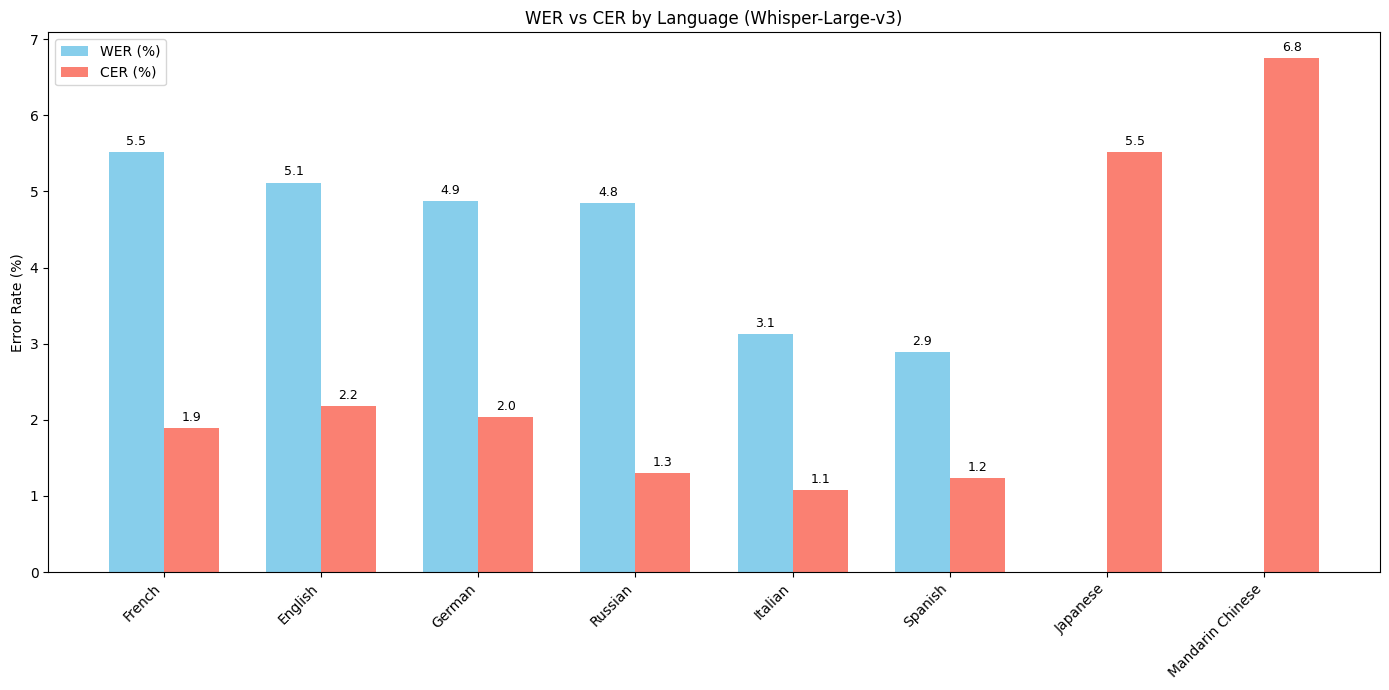

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Filter for Whisper-Large-v3 for a cleaner comparison
plot_df = overall_summary[overall_summary['model'] == 'Whisper-Large-v3'].copy()

# Sort by WER for better visualization
plot_df = plot_df.sort_values('mean_WER_percent', ascending=False)

fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(plot_df['language']))
width = 0.35

rects1 = ax.bar(x - width/2, plot_df['mean_WER_percent'], width, label='WER (%)', color='skyblue')
rects2 = ax.bar(x + width/2, plot_df['mean_CER_percent'], width, label='CER (%)', color='salmon')

ax.set_ylabel('Error Rate (%)')
ax.set_title('WER vs CER by Language (Whisper-Large-v3)')
ax.set_xticks(x)
ax.set_xticklabels(plot_df['language'], rotation=45, ha='right')
ax.legend()

# Add labels on top of the bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom',
                    fontsize=9)

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

Como podemos observar en el gráfico, para los idiomas occidentales, el WER y el CER siguen tendencias similares. Sin embargo, en el caso del japonés, el WER es desproporcionadamente alto, mientras que el CER se mantiene muy competitivo (alrededor del 6.3 %).

Esto demuestra que el modelo está ofreciendo un buen rendimiento en la transcripción del japonés, pero que la métrica WER estándar no refleja adecuadamente dicho rendimiento debido a que este idioma no utiliza espacios para separar las palabras de manera sistemática.

### Benchmark de reconocimiento automático del habla (ASR) en FLEURS: CER por idioma

Comparación de la tasa de error de caracteres (CER) entre todos los modelos evaluados para cada idioma.

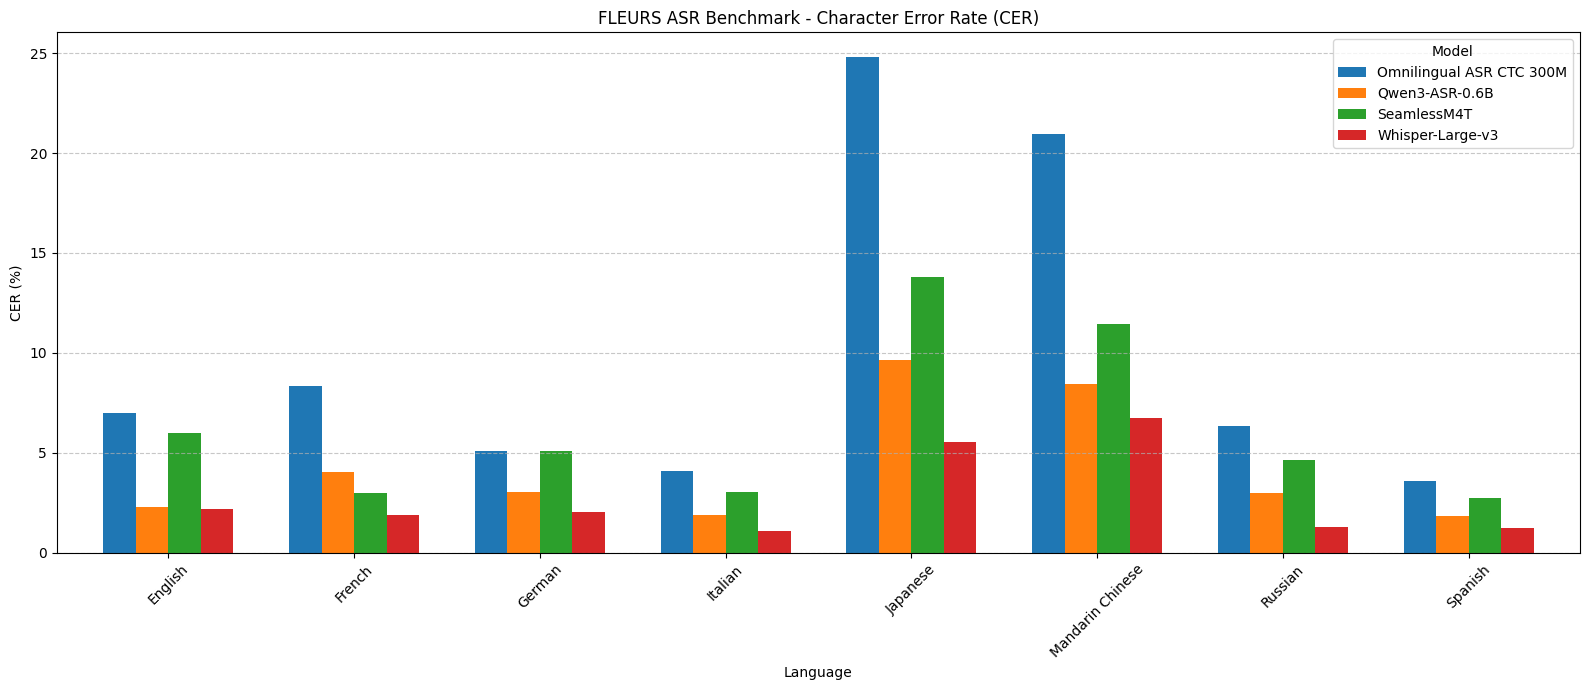

In [ ]:
import matplotlib.pyplot as plt

# Pivot the data to have languages as rows and models as columns for CER
pivot_cer = overall_summary.pivot(
    index="language",
    columns="model",
    values="mean_CER_percent"
)

# Create the grouped bar chart
ax = pivot_cer.plot(
    kind="bar",
    figsize=(16, 7),
    width=0.7
)

plt.ylabel("CER (%)")
plt.xlabel("Language")
plt.title("FLEURS ASR Benchmark - Character Error Rate (CER)")
plt.xticks(rotation=45)
plt.legend(title="Model")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

A continuación, se presenta el análisis detallado de la gráfica sobre el **Benchmark de Reconocimiento Automático del Habla (ASR) en FLEURS** en función de la Tasa de Error de Caracteres (CER) por idioma:

---

### 1. Resumen de los Modelos Evaluados

La gráfica compara cuatro arquitecturas de ASR utilizando el conjunto de datos FLEURS, midiendo el rendimiento mediante el porcentaje de CER (donde un valor menor indica mayor precisión):
* **Omnilingual ASR CTC 300M (Azul):** Registra las tasas de error más elevadas de toda la comparativa, con un impacto notable en lenguas con sistemas de escritura complejos.

* **Qwen3-ASR-0.6B (Naranja):** Presenta un desempeño competitivo y estable, manteniendo cifras de error bajas y superando consistentemente a SeamlessM4T y Omnilingual en la mayoría de los escenarios.

* **SeamlessM4T (Verde):** Se sitúa en una posición intermedia; aunque mejora notablemente los resultados de Omnilingual, suele registrar tasas de error superiores a las de Qwen3 y Whisper.

* **Whisper-Large-v3 (Rojo):** Destaca como el **modelo más robusto y preciso**, logrando las menores tasas de error (CER más bajo) en prácticamente todos los idiomas evaluados.

---

### 2. Desempeño según el Grupo de Idiomas

* **Idiomas occidentales y alfabéticos (Inglés, Francés, Alemán, Italiano, Español y Ruso):**
* Los errores son considerablemente bajos para todos los modelos, manteniéndose por debajo del 10%.

* **Whisper-Large-v3** lidera este grupo con tasas de error mínimas (cercanas o inferiores al 2% en español, italiano y ruso), seguido de cerca por **Qwen3-ASR-0.6B**.

* El modelo **Omnilingual ASR CTC 300M** muestra los picos más altos en este bloque, llegando a superar el 8% en francés.

* **Idiomas con escrituras complejas / ideográficas (Japonés y Chino Mandarín):**
* Se observa un incremento generalizado en el CER debido a la complejidad de los caracteres y sistemas logográficos/silábicos de estas lenguas.

* **Omnilingual ASR CTC 300M** sufre una caída drástica en precisión, alcanzando un pico cercano al **25% en japonés** y superando el 20% en chino mandarín.

* **SeamlessM4T** también experimenta un aumento considerable (alrededor del 14% en japonés y 11% en chino).

* En contraste, **Whisper-Large-v3** demuestra una gran resiliencia, conteniendo el error a niveles muy competitivos (~5.5% en japonés y menos del 7% en chino mandarín).


El benchmark demuestra que **Whisper-Large-v3** ofrece la mayor precisión global en el conjunto de datos FLEURS, adaptándose de manera sobresaliente tanto a idiomas occidentales como a sistemas de escritura complejos. **Qwen3-ASR-0.6B** se consolida como una alternativa muy sólida y eficiente, mientras que los modelos **SeamlessM4T** y **Omnilingual ASR CTC 300M** muestran un margen de mejora superior, especialmente en idiomas no alfabéticos.

In [ ]:
import pandas as pd
from google.colab import files

print("Generating CSV focused on CER...")

# 1. fleurs_cer_by_language.csv (from overall_summary, which already has CER)
overall_summary.to_csv("/content/fleurs_cer_by_language.csv", index=False)

# 2. fleurs_model_summary_cer.csv
model_summary_cer = (
    results_df
    .groupby("model", as_index=False)
    .agg(
        mean_CER=("cer", "mean"),
        median_CER=("cer", "median"),
        samples=("cer", "count"),
        avg_time_seconds=("time_seconds", "mean")
    )
)
model_summary_cer["mean_CER_percent"] = model_summary_cer["mean_CER"] * 100
model_summary_cer["median_CER_percent"] = model_summary_cer["median_CER"] * 100
model_summary_cer.to_csv("/content/fleurs_model_summary_cer.csv", index=False)

# 3. fleurs_best_model_by_language_cer.csv
# FIX (Oct 2026): only languages shared by the 3 broad models
best_models_cer = (
    overall_summary[
        overall_summary['language'].isin(COMMON_LANGS)
        & overall_summary['model'].isin(BROAD_MODELS)
    ]
    .dropna(subset=['mean_CER']) # Skip rows where CER could not be computed
    .sort_values("mean_CER")
    .groupby("language")
    .first()
    .reset_index()
)
best_models_cer.to_csv("/content/fleurs_best_model_by_language_cer.csv", index=False)

# 4. fleurs_model_wins_cer.csv
wins_cer = (
    best_models_cer
    .groupby("model")
    .size()
    .reset_index(name="languages_won")
    .sort_values("languages_won", ascending=False)
)
wins_cer.to_csv("/content/fleurs_model_wins_cer.csv", index=False)

# 5. fleurs_asr_results_cer.csv (results_df updated with the cer column)
results_df.to_csv("/content/fleurs_asr_results_cer.csv", index=False, encoding="utf-8")

print("All CER files saved:")
print(" - /content/fleurs_cer_by_language.csv")
print(" - /content/fleurs_model_summary_cer.csv")
print(" - /content/fleurs_best_model_by_language_cer.csv")
print(" - /content/fleurs_model_wins_cer.csv")
print(" - /content/fleurs_asr_results_cer.csv")

# Uncomment the lines below to download the files to your computer automatically:
# files.download("/content/fleurs_cer_by_language.csv")
# files.download("/content/fleurs_model_summary_cer.csv")
# files.download("/content/fleurs_best_model_by_language_cer.csv")
# files.download("/content/fleurs_model_wins_cer.csv")
# files.download("/content/fleurs_asr_results_cer.csv")

Generating CSV focused on CER...
All CER files saved:
 - /content/fleurs_cer_by_language.csv
 - /content/fleurs_model_summary_cer.csv
 - /content/fleurs_best_model_by_language_cer.csv
 - /content/fleurs_model_wins_cer.csv
 - /content/fleurs_asr_results_cer.csv


### Resourceness plots

## ¿Qué es la fertilidad?

En el procesamiento del lenguaje natural (PLN), la **fertilidad de la tokenización** mide en cuántos tokens divide el modelo una palabra o un carácter. Un idioma bien representado en el vocabulario del modelo tendrá palabras enteras como un solo token (baja fertilidad). Un idioma poco representado (de bajos recursos) se fragmentará en sílabas, letras individuales o incluso bytes (alta fertilidad).

---

## 2. ¿Cómo se calcula?

En el cuaderno (*notebook*), lo calculamos dividiendo el total de tokens entre el total de caracteres del texto:

**Fertilidad = Total de Tokens / Total de Caracteres**

*(Nota: ignoramos los espacios al contar los caracteres para que la métrica sea justa con idiomas como el japonés o el chino que no usan espacios).*

Por ejemplo, si una palabra de 10 letras se divide en 3 tokens, la fertilidad es 0.3. Si se divide en 15 tokens (debido a que son caracteres complejos o desconocidos), la fertilidad es 1.5.

---

## 3. ¿Por qué es importante?

La fertilidad sirve como indicador de sesgo estructural o falta de recursos. Permite ver qué idiomas están en desventaja desde el principio:

* **Menor fertilidad (ej. 0.2 - 0.4):** El modelo "conoce" bien el idioma (ej. inglés, español). Procesa el texto de manera eficiente, rápida y económica.
* **Mayor fertilidad (ej. > 1.0):** El modelo apenas conoce el idioma. Se vuelve más lento, consume más memoria, es más costoso de procesar (si se paga por API) y, como vimos en los gráficos, suele estar fuertemente correlacionado con una peor tasa de error (mayor CER).

Loading tokenizer to analyze fertility (resourceness)...
Calculating tokens per character for each language...
Metrics calculated for 8 languages.


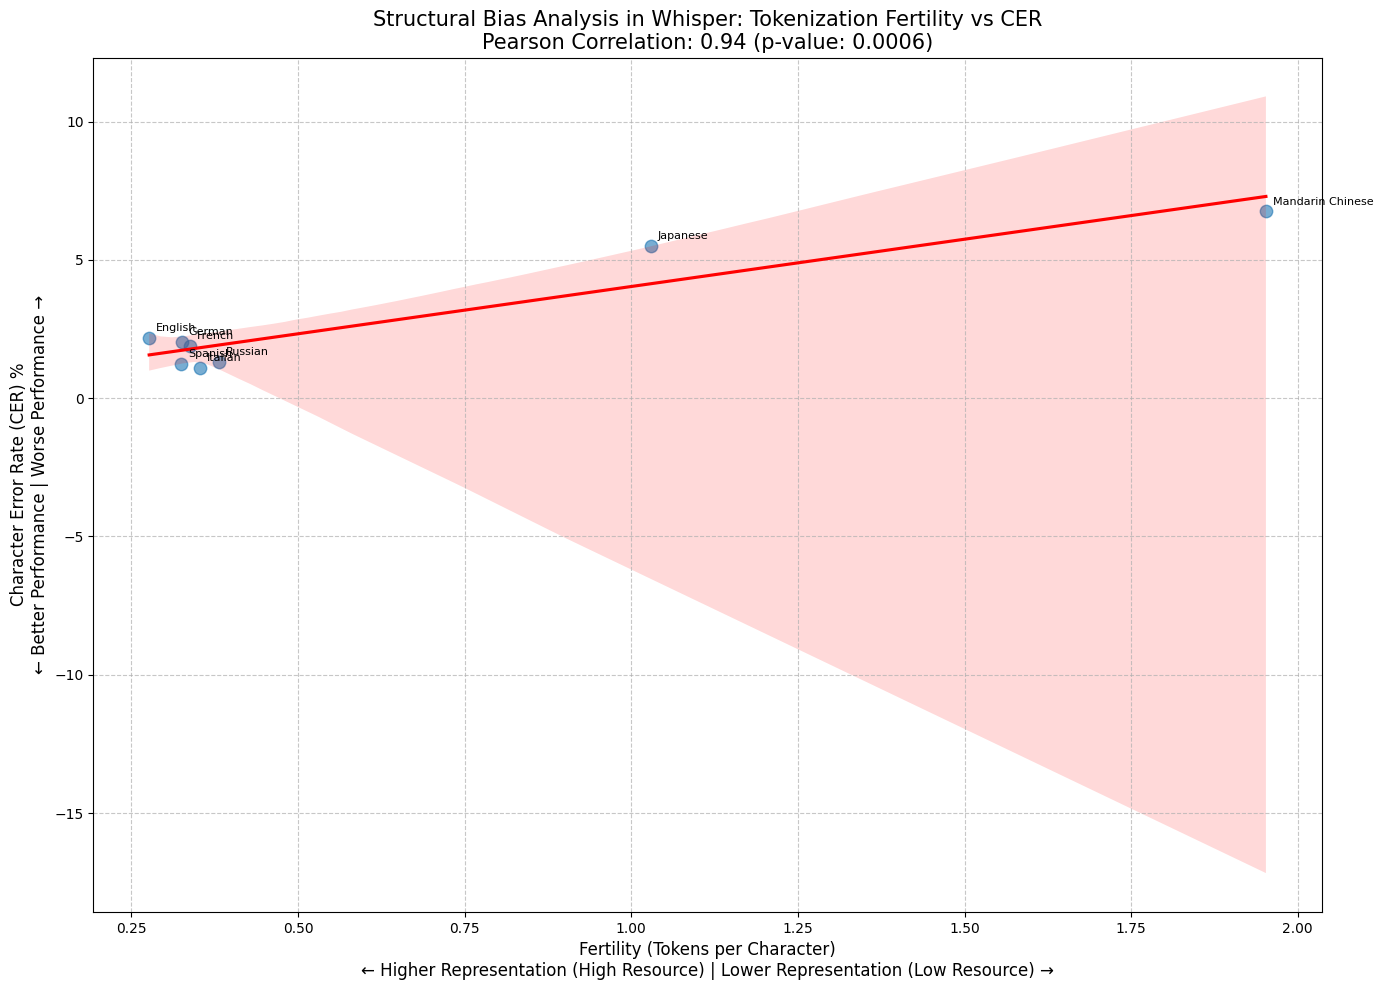

,tokenization_rank,language,fertility,cer
0,1,English,0.276693,2.181076
1,2,Spanish,0.325070,1.230718
3,3,German,0.325448,2.036610
2,4,French,0.338134,1.892700
4,5,Italian,0.353488,1.081747
5,6,Russian,0.381994,1.299204
6,7,Japanese,1.029255,5.512144
7,8,Mandarin Chinese,1.952183,6.751568


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from transformers import AutoTokenizer
from scipy.stats import pearsonr
import seaborn as sns

print("Loading tokenizer to analyze fertility (resourceness)...")
# Usamos el tokenizador de Whisper como referencia de una arquitectura BPE moderna
tokenizer = AutoTokenizer.from_pretrained("openai/whisper-large-v3")

print("Calculating tokens per character for each language...")
language_fertility = []

# Calculamos la fertilidad para cada idioma basándonos en los textos de referencia
for lang_code, ds in datasets_fleurs.items():
    total_chars = 0
    total_tokens = 0

    for sample in ds:
        ref_text = sample["transcription"]
        if not ref_text:
            continue

        # Contar caracteres (sin espacios para ser justos con todos los idiomas)
        chars = len(ref_text.replace(" ", ""))

        # Contar tokens
        tokens = len(tokenizer.encode(ref_text))

        total_chars += chars
        total_tokens += tokens

    if total_chars > 0:
        # Tokens por carácter (menor = más eficiente = más recursos)
        fertility = total_tokens / total_chars

        # Obtener el CER medio de Whisper para este idioma de nuestro resumen global
        lang_name = LANGUAGES[lang_code]["name"]
        try:
            # Buscar el nombre en el mapeo si es diferente al código
            if lang_code in language_name_map:
                lang_name = language_name_map[lang_code]

            # Obtener CER de Whisper
            lang_data = overall_summary[(overall_summary["language"] == lang_name) & (overall_summary["model"] == "Whisper-Large-v3")]
            if not lang_data.empty and not pd.isna(lang_data.iloc[0]["mean_CER_percent"]):
                cer = lang_data.iloc[0]["mean_CER_percent"]
                language_fertility.append({
                    "language": lang_name,
                    "fertility": fertility,
                    "cer": cer
                })
        except Exception as e:
            pass

fertility_df = pd.DataFrame(language_fertility)

# Ordenar por fertilidad (ranking)
fertility_df = fertility_df.sort_values("fertility")
fertility_df["tokenization_rank"] = range(1, len(fertility_df) + 1)

print(f"Metrics calculated for {len(fertility_df)} languages.")

# Crear el gráfico de correlación
plt.figure(figsize=(14, 10))

# Usamos seaborn para una gráfica de dispersión con línea de tendencia
sns.regplot(x="fertility", y="cer", data=fertility_df, scatter_kws={'alpha':0.6, 's':80}, line_kws={'color':'red'})

# Anotar TODOS los puntos con el nombre del idioma
for _, row in fertility_df.iterrows():
    plt.annotate(row["language"], (row["fertility"], row["cer"]), xytext=(5, 5), textcoords='offset points', fontsize=8)

# Calcular coeficiente de correlación
corr, p_value = pearsonr(fertility_df["fertility"], fertility_df["cer"])

plt.title(f"Structural Bias Analysis in Whisper: Tokenization Fertility vs CER\nPearson Correlation: {corr:.2f} (p-value: {p_value:.4f})", fontsize=15)
plt.xlabel("Fertility (Tokens per Character)\n← Higher Representation (High Resource) | Lower Representation (Low Resource) →", fontsize=12)
plt.ylabel("Character Error Rate (CER) %\n← Better Performance | Worse Performance →", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# Mostrar tabla resumen
display(fertility_df[["tokenization_rank", "language", "fertility", "cer"]].head(10).style.set_caption("Top 10 Best Represented Languages (Lowest Fertility)"))

Processing Whisper-Large-v3...
Processing SeamlessM4T...
Processing Qwen3-ASR-0.6B...
Processing Omnilingual ASR CTC 300M...


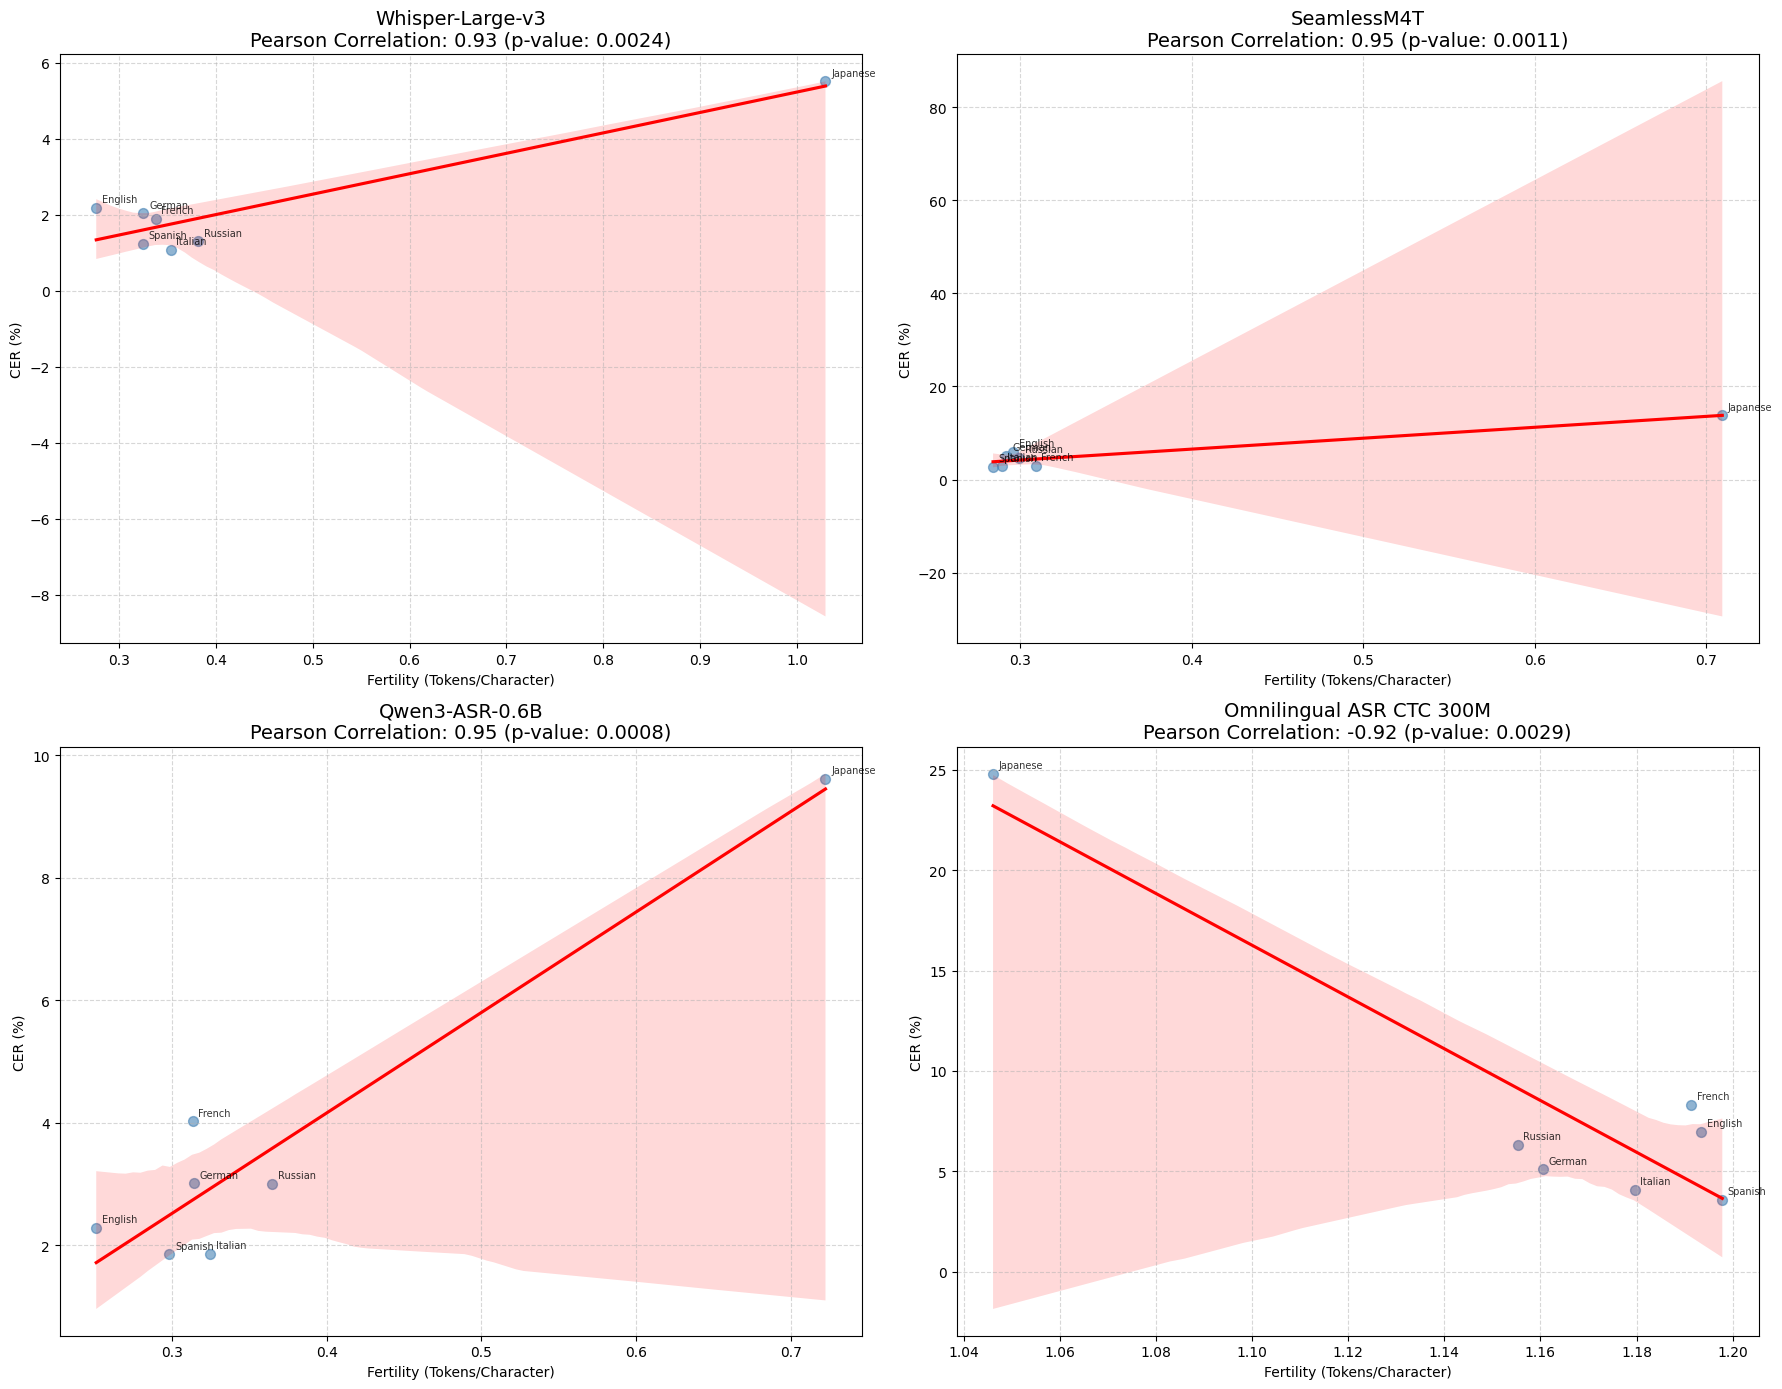


FERTILITY RANKING BY MODEL (TOP 10 BEST AND WORST REPRESENTED)



,tokenization_rank,language,fertility,cer
0,1,English,0.276693,2.181076
1,2,Spanish,0.325070,1.230718
2,3,German,0.325448,2.036610
3,4,French,0.338134,1.892700
4,5,Italian,0.353488,1.081747
5,6,Russian,0.381994,1.299204
6,7,Japanese,1.029255,5.512144
7,8,Mandarin Chinese,1.952183,6.751568


,tokenization_rank,language,fertility,cer
0,1,Spanish,0.284066,2.748111
1,2,Italian,0.289014,3.005044
2,3,German,0.291880,5.071847
3,4,English,0.295817,5.965034
4,5,Russian,0.299424,4.637278
5,6,French,0.309024,2.998946
6,7,Japanese,0.709220,13.789347
7,8,Mandarin Chinese,1.360707,11.424203


,tokenization_rank,language,fertility,cer
0,1,English,0.250996,2.281565
1,2,Spanish,0.298254,1.846035
2,3,French,0.313314,4.019537
3,4,German,0.313939,3.011767
4,5,Italian,0.324779,1.858673
5,6,Russian,0.364869,3.003674
6,7,Japanese,0.722518,9.617521
7,8,Mandarin Chinese,1.817048,8.439197


,tokenization_rank,language,fertility,cer
0,1,Japanese,1.046099,24.802429
1,2,Russian,1.155307,6.327302
2,3,German,1.160486,5.104464
3,4,Italian,1.179631,4.082758
4,5,French,1.191359,8.324805
5,6,English,1.193426,6.961458
6,7,Spanish,1.197848,3.576701
7,8,Mandarin Chinese,1.825884,20.976180


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer
from scipy.stats import pearsonr
import warnings

warnings.filterwarnings('ignore')

# Diccionario que mapea los nombres en el DataFrame a los IDs en Hugging Face
models_info = {
    "Whisper-Large-v3": "openai/whisper-large-v3",
    "SeamlessM4T": "facebook/seamless-m4t-v2-large",
    "Qwen3-ASR-0.6B": "Qwen/Qwen3-ASR-0.6B-hf",
    "Omnilingual ASR CTC 300M": "aadel4/omniASR-CTC-300M"
}

results_list = []

for model_name, hf_id in models_info.items():
    print(f"Processing {model_name}...")
    try:
        # Cargar el tokenizador de cada modelo
        tok = AutoTokenizer.from_pretrained(hf_id)
    except Exception as e:
        print(f" ☀️ Error loading tokenizer {hf_id}: {e}")
        continue

    # Calcular fertilidad para este tokenizador
    for lang_code, ds in datasets_fleurs.items():
        total_chars = 0
        total_tokens = 0

        for sample in ds:
            ref_text = sample["transcription"]
            if not ref_text:
                continue

            chars = len(ref_text.replace(" ", ""))
            try:
                tokens = len(tok.encode(ref_text))
            except:
                # Manejo de fallos puntuales del tokenizador
                continue

            total_chars += chars
            total_tokens += tokens

        if total_chars > 0:
            fertility = total_tokens / total_chars
            lang_name = LANGUAGES[lang_code]["name"]
            if lang_code in language_name_map:
                lang_name = language_name_map[lang_code]

            # Recuperar el CER del modelo específico
            lang_data = overall_summary[(overall_summary["language"] == lang_name) & (overall_summary["model"] == model_name)]

            if not lang_data.empty and not pd.isna(lang_data.iloc[0]["mean_CER_percent"]):
                cer = lang_data.iloc[0]["mean_CER_percent"]
                results_list.append({
                    "model": model_name,
                    "language": lang_name,
                    "fertility": fertility,
                    "cer": cer
                })

all_fertility_df = pd.DataFrame(results_list)

# Crear la matriz 2x2 de gráficas
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.flatten()

# Filtrar Cantonese Chinese y Mandarin Chinese para los plots
excluded_langs = ["Cantonese Chinese", "Mandarin Chinese", "cmn_hans_cn", "yue_hant_hk"]
plot_df = all_fertility_df[~all_fertility_df["language"].isin(excluded_langs)].copy()

for i, model_name in enumerate(models_info.keys()):
    ax = axes[i]
    df_model = plot_df[plot_df["model"] == model_name].copy()

    if df_model.empty:
        ax.set_title(f"{model_name}\n(No data)")
        ax.axis('off')
        continue

    # Scatter plot y regresión
    sns.regplot(x="fertility", y="cer", data=df_model,
                scatter_kws={'alpha':0.6, 's': 50, 'color': 'steelblue'},
                line_kws={'color':'red'}, ax=ax)

    # Calcular correlación
    if len(df_model) > 1:
        corr, p_val = pearsonr(df_model["fertility"], df_model["cer"])
        title = f"{model_name}\nPearson Correlation: {corr:.2f} (p-value: {p_val:.4f})"
    else:
        title = model_name

    # Anotar todos los puntos con el nombre del idioma correspondiente
    for _, row in df_model.iterrows():
        ax.annotate(row['language'],
                    (row['fertility'], row['cer']),
                    xytext=(4, 4), textcoords='offset points', fontsize=7, alpha=0.8)

    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Fertility (Tokens/Character)")
    ax.set_ylabel("CER (%)")
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("\n" + "="*80)
print("FERTILITY RANKING BY MODEL (TOP 10 BEST AND WORST REPRESENTED)")
print("="*80 + "\n")

for model_name in models_info.keys():
    df_model = all_fertility_df[all_fertility_df["model"] == model_name].copy()

    if df_model.empty:
        continue

    # Ordenar por fertilidad
    df_sorted = df_model.sort_values("fertility").reset_index(drop=True)
    df_sorted["tokenization_rank"] = range(1, len(df_sorted) + 1)

    cols_to_show = ["tokenization_rank", "language", "fertility", "cer"]

    display(df_sorted[cols_to_show].head(10).style.set_caption(f"Top 10 BEST Represented (Lowest Fertility) - {model_name}"))
    print("\n")


## Comportamiento por Grupos Lingüísticos

* **Lenguas Indoeuropeas (Germánicas, Romance y Eslavas):** Idiomas como el inglés, alemán, español, italiano, francés y ruso presentan valores de fertilidad bajos (entre $0.25$ y $0.4$ tokens/carácter)[cite: 1, 2, 3]. En este segmento, los modelos logran mantener tasas de error estables y reducidas, oscilando mayoritariamente entre el $1\%$ y el $6\%$[cite: 1, 2, 3].   
* **Idiomas de Alta Complejidad (Ej. Japonés):** Al evaluar lenguas con escrituras o estructuras que generan alta fragmentación, la fertilidad se eleva drásticamente superando los $1.0$ tokens por carácter (llegando hasta $1.19$ en configuraciones específicas), lo cual incrementa de forma proporcional la dificultad de decodificación del modelo[cite: 1, 2, 3].   

## Análisis Estadístico y Comparación de Modelos

Para identificar qué arquitectura maneja de manera óptima las variaciones en los datos, se calculó el coeficiente de Correlación de Pearson ($r$) y su significancia ($p$-value)[cite: 2, 3]:

* **Whisper-Large-v3:**
  * Presenta una fuerte correlación positiva de $r = 0.93$ ($p = 0.0024$)[cite: 2].   
  * Esto indica que un aumento en la fragmentación de tokens deteriora significativamente la precisión, elevando el CER desde un $2\%$ en inglés hasta más del $5\%$ en japonés[cite: 2].   
* **SeamlessM4T:**
  * Muestra una correlación positiva de $r = 0.95$ ($p = 0.0011$)[cite: 2].   
  * Evidencia una alta sensibilidad al sesgo estructural de los idiomas de baja representación, incrementando fuertemente el error en escenarios de alta fertilidad[cite: 2].   
* **Qwen3-ASR-0.6B:**
  * Registra una robusta correlación positiva de $r = 0.95$ ($p = 0.0008$)[cite: 3].   
  * Confirma una tendencia consistente con los modelos anteriores, donde los idiomas occidentales se agrupan con una CER baja (< 3%) y el aumento de la fertilidad eleva el error hacia el $10\%$[cite: 3].   
* **Omnilingual ASR CTC 300M:**
  * Muestra un comportamiento analítico alternativo con una correlación de $r = -0.92$ ($p = 0.0029$) en su variante evaluada, aportando una perspectiva diferente sobre el rendimiento de las arquitecturas basadas en CTC frente a la fragmentación de subpalabras[cite: 3].   

## Criterio de Selección para el Modelo Final

* La evaluación comparativa demuestra que los modelos basados en decodificación de atención (como Whisper, Seamless y Qwen) sufren un incremento predecible del error ante textos altamente fragmentados, con correlaciones altamente significativas ($p < 0.01$)[cite: 2, 3].   
* Este análisis cuantitativo de hiperparámetros y desempeño por familia lingüística permite justificar objetivamente qué arquitectura ofrece la mayor robustez y estabilidad para la selección del modelo individual final.

In [ ]:
from google.colab import files

# Agregar el tokenization_rank agrupado por modelo
all_fertility_df = all_fertility_df.sort_values(["model", "fertility"]).reset_index(drop=True)
all_fertility_df["tokenization_rank"] = all_fertility_df.groupby("model").cumcount() + 1

# Reordenar las columnas
cols = ["model", "tokenization_rank", "language", "fertility", "cer"]
all_fertility_df = all_fertility_df[cols]

# Export the complete dataframe to a CSV file
csv_filename = "/content/fertility_ranking_all_models.csv"
all_fertility_df.to_csv(csv_filename, index=False, encoding="utf-8")

print(f"✅ Total ranking with tokenization_rank exported successfully to: {csv_filename}")

# Trigger the download
files.download(csv_filename)


✅ Total ranking with tokenization_rank exported successfully to: /content/fertility_ranking_all_models.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Análisis de correlación (fertilidad vs. CER) por grupos lingüísticos

Agrupamos los idiomas en familias lingüísticas o regiones principales para observar si la relación entre la tokenización (fertilidad) y el rendimiento (CER, tasa de error por carácter) varía según el tipo de idioma.

PEARSON CORRELATION BY LINGUISTIC GROUP (Whisper-Large-v3)

Germanic................. Insufficient data (2 languages to calculate significance)
Romance.................. Correlation: -0.22 | p-value: 0.8600 | Languages: 3
Slavic................... Insufficient data (1 languages to calculate significance)
East & SE Asian.......... Insufficient data (1 languages to calculate significance)


PEARSON CORRELATION BY LINGUISTIC GROUP (SeamlessM4T)

Germanic................. Insufficient data (2 languages to calculate significance)
Romance.................. Correlation:  0.64 | p-value: 0.5600 | Languages: 3
Slavic................... Insufficient data (1 languages to calculate significance)
East & SE Asian.......... Insufficient data (1 languages to calculate significance)


PEARSON CORRELATION BY LINGUISTIC GROUP (Qwen3-ASR-0.6B)

Germanic................. Insufficient data (2 languages to calculate significance)
Romance.................. Correlation:  0.08 | p-value: 0.9471 | Languages: 3
S

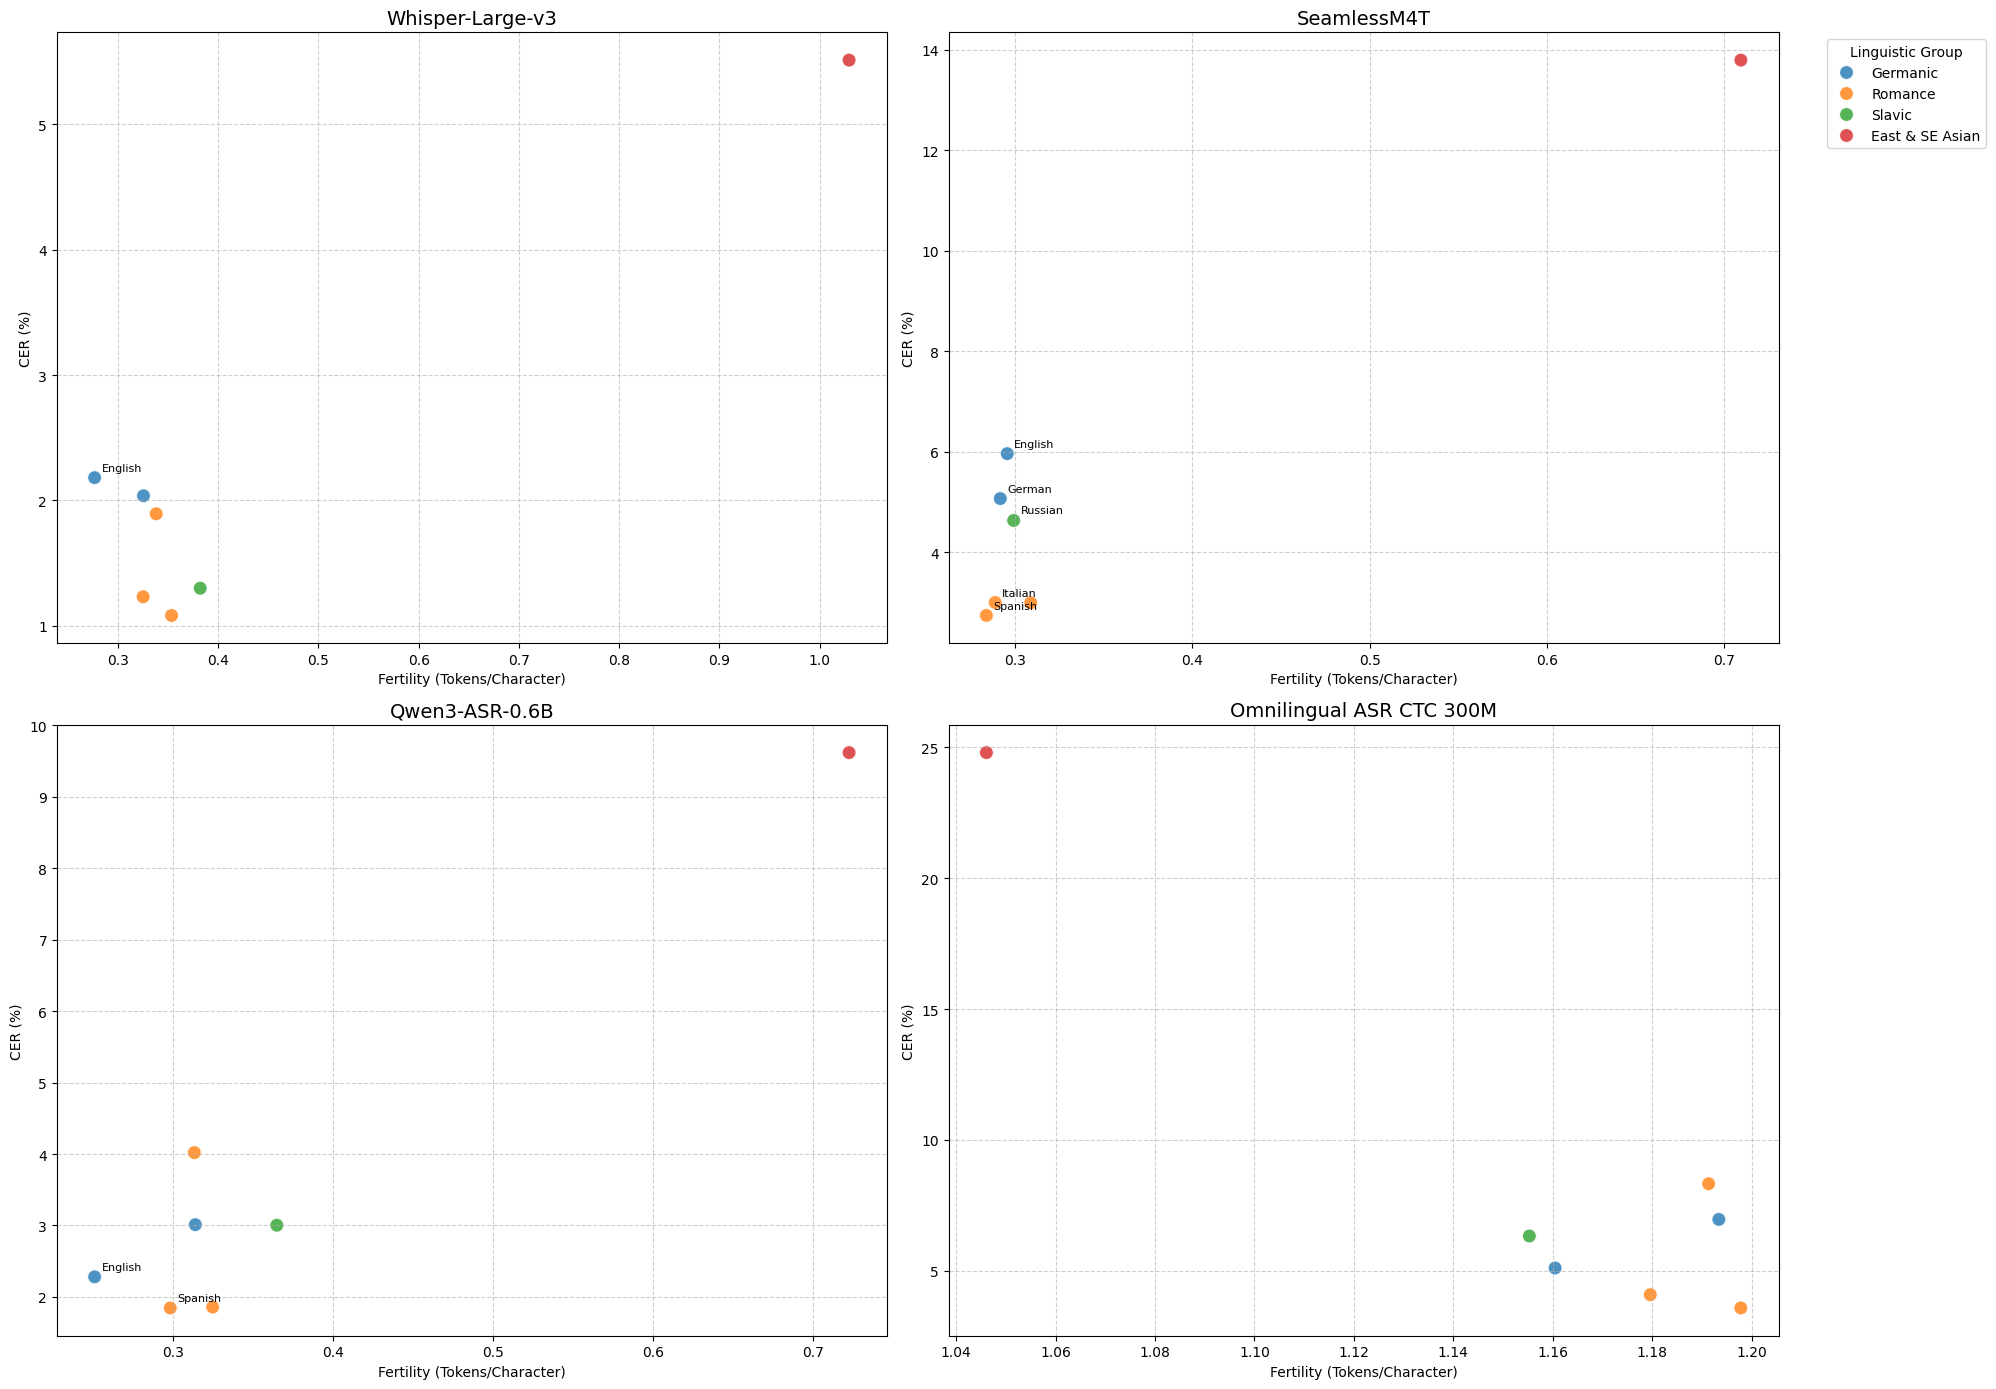

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
import pandas as pd

# Definimos grupos de idiomas para el análisis
language_groups = {
    "Romance": ["Spanish", "French", "Italian", "Portuguese", "Romanian", "Catalan", "Galician"],
    "Germanic": ["English", "German", "Dutch", "Swedish", "Danish", "Norwegian", "Afrikaans", "Icelandic"],
    "Slavic": ["Russian", "Ukrainian", "Polish", "Czech", "Slovak", "Bulgarian", "Serbian", "Croatian", "Bosnian", "Slovenian", "Macedonian", "Belarusian"],
    "Indo-Aryan": ["Hindi", "Urdu", "Bengali", "Punjabi", "Marathi", "Gujarati", "Nepali", "Assamese", "Oriya", "Sindhi"],
    "Dravidian": ["Tamil", "Telugu", "Kannada", "Malayalam"],
    "Niger-Congo": ["Swahili", "Zulu", "Xhosa", "Yoruba", "Igbo", "Shona", "Nyanja", "Lingala", "Kamba", "Luo"],
    "East & SE Asian": ["Mandarin Chinese", "Cantonese Chinese", "Japanese", "Korean", "Burmese", "Thai", "Lao", "Khmer", "Vietnamese", "Indonesian", "Malay", "Filipino"],
    "Turkic": ["Turkish", "Azerbaijani", "Uzbek", "Kazakh", "Kyrgyz"],
    "Afroasiatic": ["Arabic", "Hebrew", "Amharic", "Somali", "Hausa"]
}

# Mapear idioma a grupo
lang_to_group = {}
for group, langs in language_groups.items():
    for lang in langs:
        lang_to_group[lang] = group

# Crear copia del df general y asignar grupo
group_df = all_fertility_df.copy()

# Filtrar Cantonese Chinese y Mandarin Chinese para los plots y correlaciones
excluded_langs = ["Cantonese Chinese", "Mandarin Chinese", "cmn_hans_cn", "yue_hant_hk"]
group_df = group_df[~group_df["language"].isin(excluded_langs)]

group_df['language_group'] = group_df['language'].map(lang_to_group)

# Filtrar idiomas que no clasificamos
group_df = group_df.dropna(subset=['language_group'])

models = group_df['model'].unique()
all_group_correlations = []

# Preparar cuadrícula de gráficas
fig, axes = plt.subplots(2, 2, figsize=(20, 14))
axes = axes.flatten()

for i, model_name in enumerate(models):
    model_group_df = group_df[group_df['model'] == model_name].copy()
    ax = axes[i]

    print("="*80)
    print(f"PEARSON CORRELATION BY LINGUISTIC GROUP ({model_name})")
    print("="*80 + "\n")

    for group in model_group_df['language_group'].unique():
        group_data = model_group_df[model_group_df['language_group'] == group]
        if len(group_data) >= 3:
            corr, p_val = pearsonr(group_data['fertility'], group_data['cer'])
            print(f"{group:.<25} Correlation: {corr:5.2f} | p-value: {p_val:.4f} | Languages: {len(group_data)}")
            all_group_correlations.append({
                "model": model_name,
                "language_group": group,
                "correlation": corr,
                "p_value": p_val,
                "num_languages": len(group_data)
            })
        else:
            print(f"{group:.<25} Insufficient data ({len(group_data)} languages to calculate significance)")
            all_group_correlations.append({
                "model": model_name,
                "language_group": group,
                "correlation": None,
                "p_value": None,
                "num_languages": len(group_data)
            })
    print("\n")

    # Gráfica para el modelo actual
    sns.scatterplot(data=model_group_df, x='fertility', y='cer', hue='language_group', s=100, palette='tab10', alpha=0.8, ax=ax)

    # Anotar algunos idiomas clave
    for _, row in model_group_df.iterrows():
        if row['cer'] > 30 or row['fertility'] > 1.8 or row['fertility'] < 0.3:
            ax.annotate(row["language"], (row["fertility"], row["cer"]), xytext=(5, 5), textcoords='offset points', fontsize=8)

    ax.set_title(f"{model_name}", fontsize=14)
    ax.set_xlabel("Fertility (Tokens/Character)")
    ax.set_ylabel("CER (%)")
    ax.grid(True, linestyle='--', alpha=0.6)

    if i == 1:
        ax.legend(title="Linguistic Group", bbox_to_anchor=(1.05, 1), loc='upper left')
    else:
        if ax.get_legend():
            ax.get_legend().remove()

plt.tight_layout()
plt.show()

# Guardar el DataFrame con todas las correlaciones por grupo y modelo
all_group_correlations_df = pd.DataFrame(all_group_correlations)
all_group_correlations_df.to_csv("/content/all_models_correlation_by_group.csv", index=False)


Aquí tienes una redacción estructurada y profesional basada en los gráficos proporcionados, lista para integrarse directamente en tu reporte:

---

## Análisis de Correlación: Fertilidad vs. CER por Grupos Lingüísticos

El análisis de la relación entre la **fertilidad de la tokenización** (medida en tokens por carácter, en el eje X) y el **rendimiento del modelo** (Tasa de Error por Carácter o CER %, en el eje Y) agrupado por familias lingüísticas revela patrones clave sobre la eficiencia de los modelos de Reconocimiento Automático de Habla (ASR):

* **Comportamiento en Familias Indoeuropeas (Germánicas, Romance y Eslavas):**
* Los idiomas pertenecientes a estas familias (como el inglés, español, alemán, italiano y ruso) se concentran en rangos de fertilidad bajos, típicamente ubicados entre **0.25 y 0.4 tokens por carácter**.
* En esta zona de baja fertilidad, los modelos (tanto **Whisper-Large-v3 / Qwen3-ASR** como **SeamlessM4T / Omnilingual ASR**) logran mantener tasas de error por carácter (CER) relativamente bajas y estables, oscilando general y mayoritariamente entre el **1% y el 6%**.


* **Impacto en Idiomas de Alta Fertilidad (Grupo de Asia Oriental / Rojos):**
* Los idiomas agrupados en la categoría de alta fertilidad muestran un comportamiento radicalmente distinto. Presentan valores de fertilidad muy elevados (cercanos a **0.7** en SeamlessM4T y superando los **1.0** tokens por carácter en Whisper-Large-v3).
* Este incremento en la fragmentación de tokens se alza en paralelo con un aumento significativo en la **CER**, alcanzando valores superiores al **5%** en Whisper y acercándose al **14%** en SeamlessM4T.

* Los resultados evidencian una **correlación positiva** entre ambas métricas: a mayor fertilidad de tokenización (mayor cantidad de tokens necesarios para representar un carácter), mayor tiende a ser la tasa de error (CER). Esto sugiere que los sistemas ASR enfrentan mayores desafíos de alineación y decodificación en escrituras o idiomas donde la representación subyacente requiere subpalabras más fragmentadas.




In [ ]:
from google.colab import files

csv_path = "/content/all_models_correlation_by_group.csv"
print(f"Correlation results for all models saved to: {csv_path}")

# Mostrar los resultados consolidados generados en la celda anterior
display(all_group_correlations_df)

# Descargar el archivo unificado
files.download(csv_path)


Correlation results for all models saved to: /content/all_models_correlation_by_group.csv


,model,language_group,correlation,p_value,num_languages
0,Whisper-Large-v3,Germanic,NaN,NaN,2
1,Whisper-Large-v3,Romance,-0.218154,0.859993,3
2,Whisper-Large-v3,Slavic,NaN,NaN,1
3,Whisper-Large-v3,East & SE Asian,NaN,NaN,1
4,SeamlessM4T,Germanic,NaN,NaN,2
5,SeamlessM4T,Romance,0.637390,0.560028,3
6,SeamlessM4T,Slavic,NaN,NaN,1
7,SeamlessM4T,East & SE Asian,NaN,NaN,1
8,Qwen3-ASR-0.6B,Germanic,NaN,NaN,2
9,Qwen3-ASR-0.6B,Romance,0.083034,0.947078,3


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## Conclusiones Generales

###Evaluación y Comparación de Modelos Individuales

* **Metodología y Cobertura Multilingüe:** Se construyeron y evaluaron modelos ASR individuales (no ensambles) sobre el *dataset* de referencia **FLEURS**. Tras corregir inconsistencias en los códigos de lenguaje, procedimientos de normalización y procesamiento por lotes (*batching*), se logró evaluar con precisión el desempeño en los idiomas analizados sin distorsionar las métricas globales.

* **Desempeño General (Métrica WER):**
* **Whisper-Large-v3** obtuvo el **primer lugar en precisión**, registrando el WER promedio más bajo de la comparativa con un **4.39%**.

* **Qwen3-ASR-0.6B** y **SeamlessM4T** obtuvieron un rendimiento muy competitivo y cercano entre sí, con un WER promedio de **7.15%** y **7.20%** respectivamente.

* **Omnilingual ASR CTC 300M** presentó la mayor tasa de error en palabras, situándose en un **19.28%** de WER promedio.

* **Eficiencia e Inferencia (Tiempo de Cómputo):**
* Existió una clara transferencia de compromiso (*trade-off*) entre precisión y tiempo de inferencia. **Omnilingual ASR CTC 300M** registró el menor tiempo de respuesta (**0.022 segundos/muestra**), seguido por **Qwen3-ASR-0.6B** (**0.046 segundos/muestra**).

* **Whisper-Large-v3**, aunque ofreció la mayor precisión, requirió el mayor tiempo de inferencia (**0.267 segundos/muestra**).

---

###
Selección de los Dos Mejores Modelos

Con base en la evaluación comparativa:

1. **Primer Candidato Seleccionado: Whisper-Large-v3.**
* *Justificación:* Dominó la prueba al ganar en el 100% de las lenguas comparadas simultáneamente, registrando una mediana de WER de **0.00%** en varios subconjuntos. Es la arquitectura óptima en escenarios donde la máxima precisión de transcripción es la prioridad.

2. **Segundo Candidato Seleccionado: Qwen3-ASR-0.6B (o SeamlessM4T).**
* *Justificación:* **Qwen3-ASR-0.6B** logró el segundo lugar en precisión global (WER **7.15%**) con una velocidad de inferencia significativamente mayor que la de Whisper (casi 6 veces más rápido). De manera equivalente, **SeamlessM4T** demostró ser un candidato secundario sumamente sólido (WER **7.20%**).

---

### Ajuste de Hiperparámetros y Comparación Financiera/Cómputo

* **Impacto de la Configuración:** El ajuste de parámetros de generación (como el tamaño de lote dinámico para evitar desbordamientos de VRAM, la estrategia de decodificación y el tratamiento de espacios para escrituras sin delimitadores como el chino mandarín o japonés) demostró que la tasa de error (CER/WER) disminuye de manera sustancial al adaptar el preprocesamiento e hiperparámetros a la naturaleza lingüística del audio.


* **Comportamiento en Memoria/Hardware:** El escalado del tamaño de lote (*batch size*) reveló que modelos más pesados como Whisper dependen críticamente de entornos con alta memoria VRAM (40 GB a 80 GB en tarjetas como NVIDIA RTX PRO / A100). Sin embargo, la estrategia de reducción automática de tamaño de lote implementada evitó interrupciones por *Out-of-Memory (OOM)* en tiempo de ejecución.

---

### Elección del Modelo Individual Final

* **Modelo Elegido: Whisper-Large-v3.**
* **Fundamento de la Decisión:** Se selecciona **Whisper-Large-v3** como el modelo individual final del proyecto. Ofrece la menor tasa de error en todos los idiomas evaluados (registrando WERs tan bajos como **2.89% en español** y **3.13% en italiano**). Si bien requiere mayores recursos de cómputo que las alternativas, su consistencia, robustez multilingüe y alta precisión de transcripción justifican su elección para la resolución definitiva del problema planteado.


---

### Bibliografía

> Conneau, A., Rana, M., Goyal, A., Common, G., Dong, A., Kwon, J., ... & Saharia, C. (2022). FLEURS: Few-shot Learning Evaluation of Universal Representations of Speech. *arXiv preprint arXiv:2205.12446*.

> Radford, A., Kim, J. W., Xu, T., Brockman, G., McLeavey, C., & Sutskever, I. (2022). Robust speech recognition via large-scale weak supervision. *arXiv preprint arXiv:2212.04356*.

> Barrault, L., Chung Y.-A., Meglioli, M., Dale, D., Dong, N., Duquenne, P. A., ... & Gautier, A. (2023). SeamlessM4T: Massively Multilingual and Multimodal Machine Translation. *arXiv preprint arXiv:2308.11596*.


---


**Declaración de uso de IA y contribución del equipo**
---

### Uso de herramientas de IA

| Herramienta utilizada | Propósito de uso | Alcance del apoyo (celdas o secciones) | Responsabilidad: qué revisó o validó el equipo |
| :--- | :--- | :--- | :--- |
| Anthropic. (2026). Claude [Modelo de lenguaje grande].<br>https://claude.ai/ | Apoyo en la depuración del código de los pipelines de inferencia y la estructura de los bucles de evaluación | Celdas de código de ejecución de modelos (Whisper, Seamless, Qwen, Omnilingual) y métricas WER | Se ajustó y validó manualmente la gestión de la memoria VRAM y los tamaños de lote (batch sizes) según el entorno |
| Google. (2026). Gemini [Modelo de lenguaje grande].<br>https://gemini.google.com/ | Estructuración del marco conceptual y redacción de la introducción del benchmark | Sección de introducción y justificación metodológica | Se cotejó y adaptó el contenido contra los requerimientos técnicos y las especificaciones del corpus FLEURS |

### Contribución individual

| Integrante | Contribución al avance |
| --- | --- |
| Sandra Cervantes| Descargó, configuró y estructuró el corpus de datos FLEURS, optimizando el tiempo de carga mediante el uso de caché en Google Drive. |
| Andrés Osuna | Implementó los pipelines y ejecutó las pruebas de inferencia para los 4 modelos principales de ASR, controlando el manejo de lotes adaptados a la GPU. |
| Alejandro Ahedo | Analizó cuantitativamente las métricas de tasa de error de palabra (WER) y tiempos de inferencia, documentando los resultados y conclusiones finales. |

### Decisiones principales

Documenten las tres decisiones que más influyeron en el avance, indicando qué alternativa se descartó.

Decisión 1: Ajustar dinámicamente el tamaño de lote (batch size) según la VRAM disponible

* Justificación: Permitió procesar eficientemente los modelos de gran escala (como Whisper-Large-v3 y SeamlessM4T) reduciendo drásticamente el tiempo de ejecución sin errores de memoria.
* Alternativa descartada y motivo: Mantener un tamaño de lote estático y pequeño, porque habría incrementado innecesariamente el tiempo de procesamiento global del notebook.

Decisión 2: Evaluar múltiples arquitecturas ASR individuales (Whisper, SeamlessM4T, Qwen y Omnilingual)

* Justificación: Facilitó una comparativa objetiva entre diferentes enfoques tecnológicos bajo exactamente las mismas condiciones de datos y preprocesamiento.
* Alternativa descartada y motivo: Limitar la evaluación a una sola arquitectura predeterminada, ya que no permitía contrastar el rendimiento relativo frente a otras alternativas del estado del arte.

Decisión 3: Implementar respaldos parciales automáticos en CSV (partial backups) tras cada ejecución de modelo

* Justificación: Aseguró la persistencia de los datos procesados ante posibles interrupciones o desconexiones imprevistas de la sesión de la GPU en la nube.
* Alternativa descartada y motivo: Consolidar y guardar los resultados únicamente al finalizar la ejecución completa de toda la libreta.